*  DSC630-T303 Predictive Analytics (2267-1)
*  10.2 Assignment: Recommender System
*  David Jorgensen

# 10.2 Assignment: Recommender System

## Objective

Build a recommender system on the small MovieLens data set (`ml-latest-small`)
that takes **one movie the user likes** as input and returns **ten other movies**
to watch.

## Approach

The system is a **hybrid item-to-item recommender**, combining two independent
notions of "these two movies go together":

1. **Item-based collaborative filtering (the primary signal).** Two movies are
   similar if the same people tended to rate them the same way, relative to how
   that person rates movies in general; the item-based CF method of Sarwar et
   al. (2001), with similarities *shrunk* toward zero when only a handful of
   people rated both movies (Bell & Koren, 2007).
2. **Content-based filtering (the supporting signal).** Two movies are similar if
   their genre labels and user tags use similar vocabulary, measured by TF-IDF
   cosine similarity.

The two matrices are put on a common per-row scale and blended. Collaborative
filtering carries most of the weight because it captures actual audience taste,
while the content signal supplies topical coherence and rescues movies with too
few ratings for the collaborative signal to be reliable. The system is evaluated
against **random** and **popularity** baselines on held-out ratings, using both
ranking metrics and a metric built for the "people who liked X also liked Y"
claim it makes.

Item-to-item is the right shape for this task. The assignment asks for
recommendations from a **single input movie**, not a full user profile
Item-to-item answers "given this one movie, what else?", and is what 
makes Amazon-style "customers who bought this also bought" panels work 
(Linden et al., 2003).

## References

* Sarwar, B., Karypis, G., Konstan, J., & Riedl, J. (2001). *Item-based
  collaborative filtering recommendation algorithms.* WWW '01.
  <https://dl.acm.org/doi/10.1145/371920.372071>
* Linden, G., Smith, B., & York, J. (2003). *Amazon.com recommendations:
  item-to-item collaborative filtering.* IEEE Internet Computing 7(1).
  <https://doi.org/10.1109/MIC.2003.1167344>
* Bell, R. & Koren, Y. (2007). *Scalable collaborative filtering with jointly
  derived neighborhood interpolation weights.* ICDM '07. (Source of the
  shrinkage term `n / (n + lambda)` used to damp low-support similarities.)
  <https://doi.org/10.1109/ICDM.2007.90>
* Cremonesi, P., Koren, Y., & Turrin, R. (2010). *Performance of recommender
  algorithms on top-N recommendation tasks.* RecSys '10. (Source of the
  sampled-negatives evaluation protocol, and of the finding that a popularity
  baseline is unusually hard to beat on offline top-N metrics.)
  <https://doi.org/10.1145/1864708.1864721>
* Steck, H. (2011). *Item popularity and recommendation accuracy.* RecSys '11.
  (Explains the popularity bias in offline evaluation addressed in Step 12.)
  <https://doi.org/10.1145/2043932.2043957>
* Harper, F. M. & Konstan, J. A. (2015). *The MovieLens datasets: history and
  context.* ACM TiiS 5(4). <https://doi.org/10.1145/2827872> (Required citation
  for the data set.)
* scikit-learn documentation for `TfidfVectorizer` and `cosine_similarity`.
  <https://scikit-learn.org/stable/modules/metrics.html#cosine-similarity>

## Step 1: Import libraries and set the configuration constants

Every tuning constant used in the notebook is defined here in one place, so the
pipeline can be re-run under different settings by editing a single cell. The
values are justified in Step 12, where they are tuned on a validation split.

In [ ]:
# Standard data handling and numerics.
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import difflib
import re
import matplotlib.pyplot as plt

# Display options
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

# ----------------------------------------------------------------------
# CONFIGURATION -- every tunable constant in the notebook lives here.
# ----------------------------------------------------------------------
DATA_DIR = "data"      # folder holding the MovieLens CSV files
# A movie needs at least this many ratings to be eligible for recommendation.
# Movies rated by only one or two people produce meaningless similarity scores.
MIN_RATINGS = 10
# Shrinkage strength. A similarity computed from n co-raters is multiplied by
# n / (n + SHRINKAGE). Small n therefore gets pulled hard toward zero.
SHRINKAGE = 20
# Blend weight: how much of the final score comes from collaborative filtering.
# The remaining (1 - W_CF) comes from the content-based signal.
W_CF = 0.75
# Number of recommendations to return.
TOP_N = 10
# Fixed seed so every random operation in the notebook is reproducible.
RANDOM_STATE = 42

## Step 2: Load the data and inspect what is in it

The `ml-latest-small` data set ships as four CSV files. Three of them matter here:

| File | Contents | Role in this system |
|---|---|---|
| `ratings.csv` | `userId, movieId, rating, timestamp` | The collaborative signal. Who rated what, and how highly. |
| `movies.csv` | `movieId, title, genres` | Titles for display, genres for the content signal. |
| `tags.csv` | `userId, movieId, tag, timestamp` | Free-text keywords, added to the content signal. |
| `links.csv` | `movieId, imdbId, tmdbId` | External IDs only. Not used -- nothing here informs similarity. |

Ratings are on a 0.5-5.0 scale in half-star steps.

In [2]:
# Load the three files the recommender needs.
ratings = pd.read_csv(f"{DATA_DIR}/ratings.csv")
movies = pd.read_csv(f"{DATA_DIR}/movies.csv")
tags = pd.read_csv(f"{DATA_DIR}/tags.csv")

# movieId -> title, used for display everywhere below.
title_lookup = movies.set_index("movieId")["title"].to_dict()

print(f"ratings.csv : {ratings.shape[0]:>7,} rows x {ratings.shape[1]} columns")
print(f"movies.csv  : {movies.shape[0]:>7,} rows x {movies.shape[1]} columns")
print(f"tags.csv    : {tags.shape[0]:>7,} rows x {tags.shape[1]} columns")

# Integrity checks on the fields the model depends on.
missing = (ratings[["userId", "movieId", "rating"]].isna().sum().sum()
           + movies[["movieId", "title", "genres"]].isna().sum().sum())
print(f"\nMissing values in modeled columns : {missing}")
print(f"Duplicate movieIds in movies.csv  : {movies.movieId.duplicated().sum()}")

# Headline counts describing the data set.
n_users = ratings.userId.nunique()
n_rated_movies = ratings.movieId.nunique()

# Density = what fraction of the full user x movie grid is actually filled in.
# This number is the central difficulty of every recommender problem.
density = len(ratings) / (n_users * n_rated_movies)
span = pd.to_datetime(ratings.timestamp, unit="s")

print(f"\nDistinct users        : {n_users:,}")
print(f"Movies in the catalog : {movies.movieId.nunique():,} "
      f"({n_rated_movies:,} of them have at least one rating)")
print(f"Total ratings         : {len(ratings):,}")
print(f"Rating matrix density : {density:.2%}  "
      f"({100 - density * 100:.2f}% of the grid is empty)")
print(f"Ratings span          : {span.min():%Y-%m-%d} to {span.max():%Y-%m-%d}")

# Confirm the expected layout of the two tables the model reads.
display(ratings.head(3))
display(movies.head(3))

ratings.csv : 100,836 rows x 4 columns
movies.csv  :   9,742 rows x 3 columns
tags.csv    :   3,683 rows x 4 columns

Missing values in modeled columns : 0
Duplicate movieIds in movies.csv  : 0

Distinct users        : 610
Movies in the catalog : 9,742 (9,724 of them have at least one rating)
Total ratings         : 100,836
Rating matrix density : 1.70%  (98.30% of the grid is empty)
Ratings span          : 1996-03-29 to 2018-09-24


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


## Step 3: Exploratory analysis

Three properties of this data set determine the design decisions made later, so
they are established with numbers before any modeling happens:

1. **How ratings are distributed**: this motivates mean-centering in Step 4.
2. **How unevenly ratings are spread across movies**: this motivates the
   `MIN_RATINGS` filter and the shrinkage term in Step 5.
3. **How much users differ in their personal rating scales**: this is the
   specific bias that mean-centering removes.

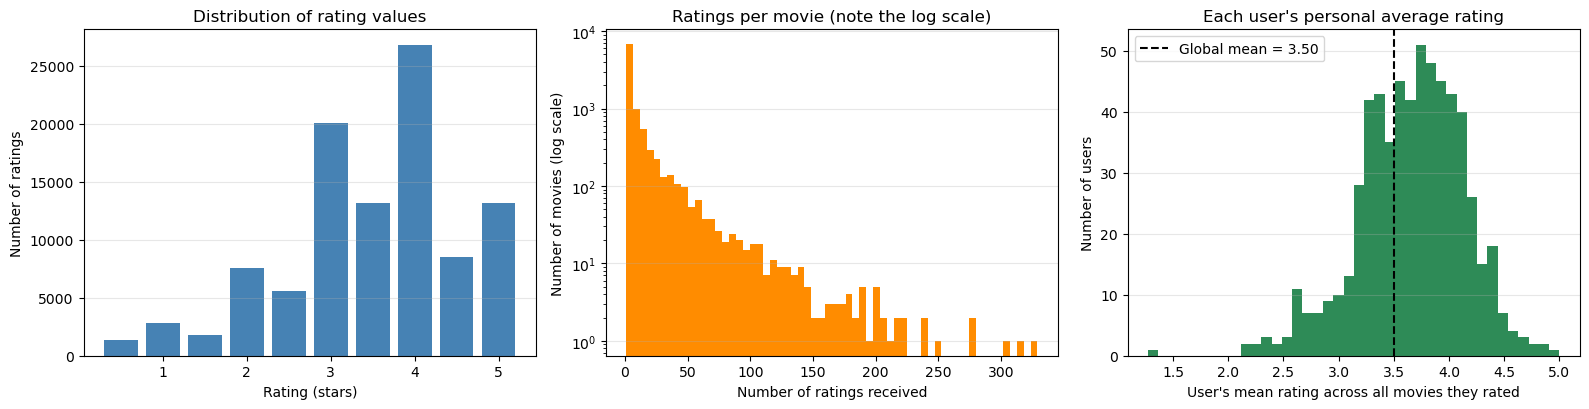

Mean rating: 3.50    Share of ratings >= 4.0 stars: 48.2%    Median ratings per movie: 3
Per-user averages run from 1.27 to 5.00 stars (standard deviation 0.48).

Catalog size and rating coverage at various thresholds:
 Min ratings  Movies kept  % of movies kept  % of all ratings kept
           1         9724             100.0                  100.0
           2         6278              64.6                   96.6
           5         3650              37.5                   89.5
          10         2269              23.3                   80.4
          20         1297              13.3                   67.3
          50          450               4.6                   41.0
         100          138               1.4                   20.0


In [3]:
# ---- Three views of the data, one per design decision.
per_movie = ratings.groupby("movieId").size()
user_means = ratings.groupby("userId")["rating"].mean()
rating_counts = ratings.rating.value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].bar(rating_counts.index, rating_counts.values, width=0.4, color="steelblue")
axes[0].set_title("Distribution of rating values")
axes[0].set_xlabel("Rating (stars)")
axes[0].set_ylabel("Number of ratings")

# Log y-axis because the ratings-per-movie distribution is extremely skewed.
axes[1].hist(per_movie.values, bins=60, color="darkorange")
axes[1].set_yscale("log")
axes[1].set_title("Ratings per movie (note the log scale)")
axes[1].set_xlabel("Number of ratings received")
axes[1].set_ylabel("Number of movies (log scale)")

axes[2].hist(user_means, bins=40, color="seagreen")
axes[2].axvline(ratings.rating.mean(), color="black", linestyle="--",
                label=f"Global mean = {ratings.rating.mean():.2f}")
axes[2].set_title("Each user's personal average rating")
axes[2].set_xlabel("User's mean rating across all movies they rated")
axes[2].set_ylabel("Number of users")
axes[2].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mean rating: {ratings.rating.mean():.2f}    "
      f"Share of ratings >= 4.0 stars: {(ratings.rating >= 4.0).mean():.1%}    "
      f"Median ratings per movie: {per_movie.median():.0f}")
print(f"Per-user averages run from {user_means.min():.2f} to {user_means.max():.2f} "
      f"stars (standard deviation {user_means.std():.2f}).")

# ---- The trade-off that sets MIN_RATINGS.
print("\nCatalog size and rating coverage at various thresholds:")
rows = [{"Min ratings": t,
         "Movies kept": int((per_movie >= t).sum()),
         "% of movies kept": 100 * (per_movie >= t).mean(),
         "% of all ratings kept": 100 * per_movie[per_movie >= t].sum() / len(ratings)}
        for t in [1, 2, 5, 10, 20, 50, 100]]
print(pd.DataFrame(rows).round(1).to_string(index=False))

**Ratings are skewed high.** The mean rating is 3.50 and nearly half of all
ratings (48.2%) are 4 stars or better, because people mostly rate movies they
chose to watch and mostly chose things they expected to like. A raw rating of 4.0
therefore does not by itself mean "this person loved it": it has to be read
relative to how that person rates everything else, which is what mean-centering
in Step 4 does.

**Ratings per movie follow a long tail.** The histogram needs a log scale to be
readable, the signature of a power-law-ish distribution: a few hundred
blockbusters absorb most of the ratings while the median movie has just 3. The
threshold table is the trade-off that sets `MIN_RATINGS`: requiring at least 10
ratings discards roughly three quarters of the *titles* but keeps roughly 80% of
the *ratings*, because the titles dropped are precisely the ones almost nobody
rated. `MIN_RATINGS = 10` is the value used.

**Users are on genuinely different scales.** The gap between the most generous
and the most severe user is on the order of three full stars, so two users can
feel identically about a movie and record ratings two stars apart. Cosine
similarity on *raw* ratings would treat two generous users as similar simply
because both gave high numbers to everything. Subtracting each user's own mean
first converts every rating into "how far above or below this person's normal did
this movie land", which is comparable across users, which is the standard *adjusted
cosine* similarity of Sarwar et al. (2001).

## Step 4: Filter the catalog and build the mean-centered item-user matrix

Three operations happen in this step, in order:

1. **Filter** to movies with at least `MIN_RATINGS` ratings.
2. **Mean-center** every rating by subtracting the rating user's personal average.
3. **Pivot** into a sparse matrix with one row per movie and one column per user.

The matrix is deliberately oriented **movies x users** rather than users x movies,
because the similarities being computed are between *movies*, and
`cosine_similarity` operates row-wise.

**Why the filter is not optional.** Cosine similarity between two movies rated by
only one person in common is mathematically forced to be exactly +/-1.0: with a
single shared dimension the two vectors are necessarily parallel or
anti-parallel, so the "perfect similarity" is an artifact of having one data
point rather than evidence of a relationship. Measured on the unfiltered data,
**127,117 movie pairs score above 0.999 similarity and 100% of them rest on two
co-raters or fewer**; even at a 0.5 similarity bar the median pair is backed by a
single co-rater. Unfiltered, a documentary with one rating has dozens of movies
tied at a flawless 1.000, and those would be served as the system's most
confident suggestions. The `MIN_RATINGS` filter removes movies that lack the
evidence to be described at all, and the shrinkage term in Step 5 handles what
survives the filter.

In [4]:
# ---- Operation 1: filter to movies with enough ratings to be reliable.
eligible_ids = per_movie[per_movie >= MIN_RATINGS].index
work = ratings[ratings.movieId.isin(eligible_ids)].copy()

print(f"Filter: keeping movies with >= {MIN_RATINGS} ratings")
print(f"  Movies  : {ratings.movieId.nunique():,} -> {work.movieId.nunique():,}")
print(f"  Ratings : {len(ratings):,} -> {len(work):,} "
      f"({len(work) / len(ratings):.1%} of the original ratings retained)")

# ---- Operation 2: mean-center each rating against its user's own average.
# transform("mean") broadcasts each user's average back onto all of their rows,
# so the subtraction lines up element-wise without an explicit merge. A positive
# result means the user liked this movie more than their own typical movie.
work["centered"] = (work["rating"]
                    - work.groupby("userId")["rating"].transform("mean"))

# ---- Operation 3: pivot into a sparse movies x users matrix.
# pandas 'category' dtype assigns each movieId/userId a compact integer code,
# which becomes its row/column position in the matrix.
movie_cat = work.movieId.astype("category")
user_cat = work.userId.astype("category")

# movie_ids[i] is the MovieLens movieId of matrix row i. This array is the
# bridge between matrix positions and real movies, and is used constantly below.
movie_ids = np.array(movie_cat.cat.categories)
row_of_movie = {mid: i for i, mid in enumerate(movie_ids)}

# Build the sparse matrix directly from (value, (row, col)) triplets. Only the
# observed ratings are stored; the empty cells cost nothing.
item_user = csr_matrix(
    (work.centered.values, (movie_cat.cat.codes, user_cat.cat.codes)),
    shape=(len(movie_ids), user_cat.cat.categories.size),
)

dense_mb = np.prod(item_user.shape) * 8 / 1e6
sparse_mb = (item_user.data.nbytes + item_user.indices.nbytes
             + item_user.indptr.nbytes) / 1e6
print(f"\nItem-user matrix : {item_user.shape} (movies x users), "
      f"{item_user.nnz:,} stored cells, "
      f"{item_user.nnz / np.prod(item_user.shape):.2%} dense")
print(f"Memory           : {sparse_mb:.1f} MB sparse vs {dense_mb:.1f} MB dense")

Filter: keeping movies with >= 10 ratings
  Movies  : 9,724 -> 2,269
  Ratings : 100,836 -> 81,116 (80.4% of the original ratings retained)

Item-user matrix : (2269, 610) (movies x users), 81,116 stored cells, 5.86% dense
Memory           : 1.0 MB sparse vs 11.1 MB dense


## Step 5: Collaborative signal, shrunk adjusted-cosine item similarity

### The similarity measure

Each movie is now a vector of mean-centered ratings across users. The similarity
between movies $i$ and $j$ is the cosine of the angle between their vectors,
taken over the users $U$ who rated both:

$$\text{sim}(i,j) = \frac{\sum_{u \in U}(r_{ui}-\bar{r_u})(r_{uj}-\bar{r_u})}
{\sqrt{\sum_{u \in U}(r_{ui}-\bar{r_u})^2}\sqrt{\sum_{u \in U}(r_{uj}-\bar{r_u})^2}}$$

Because the ratings were centered by user mean in Step 4, this is the **adjusted
cosine similarity** of Sarwar et al. (2001). It ranges from -1 (people who liked
one disliked the other) through 0 (no relationship) to +1 (agreement).

### The shrinkage correction

Raw cosine ignores *how much evidence* it is based on: a 0.95 from 3 co-raters
looks identical to a 0.95 from 300. The standard fix is to shrink each similarity
toward zero in proportion to its support (Bell & Koren, 2007):

$$\text{sim}_{\text{shrunk}}(i,j) = \frac{n_{ij}}{n_{ij}+\lambda}\cdot \text{sim}(i,j)$$

where $n_{ij}$ is the number of users who rated both movies and $\lambda$ is
`SHRINKAGE`. With $\lambda = 20$, a pair with 20 co-raters keeps half its
similarity, a pair with 200 keeps about 91%, and a pair with 3 keeps only 13%.
Well-supported relationships are left essentially intact while thin ones are
suppressed. The median eligible movie pair has only 4 co-raters, so this
correction does continuous work across the whole matrix rather than only at the
extremes: it moves the top neighbours of a typical movie from pairs backed by
about 40 shared raters to pairs backed by 80-180, while leaving obviously
correct pairs alone (*The Godfather* to *Godfather Part II*, 125 co-raters, stays
firmly on top).

In [5]:
# ---- Raw adjusted-cosine similarity between every pair of movies.
cf_raw = cosine_similarity(item_user, dense_output=True)

# A movie is trivially identical to itself; zero the diagonal so a movie can
# never be recommended as similar to itself.
np.fill_diagonal(cf_raw, 0.0)

# ---- Count co-raters for every movie pair. Converting the matrix to binary
# (rated / not rated) and multiplying it by its own transpose gives, in cell
# (i, j), the number of users who rated both i and j.
binary_iu = (item_user != 0).astype(np.float32)
co_counts = np.asarray((binary_iu @ binary_iu.T).todense())

# ---- Apply the shrinkage factor n / (n + lambda).
shrink_factor = co_counts / (co_counts + SHRINKAGE)
cf_sim = cf_raw * shrink_factor
np.fill_diagonal(cf_sim, 0.0)

print(f"Collaborative similarity matrix : {cf_sim.shape}, "
      f"{cf_sim.nbytes / 1e6:.1f} MB")
print(f"Median co-raters per movie pair : {np.median(co_counts):.0f}")
print(f"Value range after shrinkage     : {cf_sim.min():.3f} to {cf_sim.max():.3f}")

Collaborative similarity matrix : (2269, 2269), 41.2 MB
Median co-raters per movie pair : 4
Value range after shrinkage     : -0.251 to 0.677


## Step 6: Content signal, TF-IDF over genres and tags

The collaborative signal has one structural weakness: it only knows what the
*crowd* did, so it drifts toward whatever is broadly popular among a movie's
audience. Ask it for movies like *Toy Story* and it will suggest
*Raiders of the Lost Ark*, not because they are alike but because Pixar fans in
this data set also rated Indiana Jones highly.

The content signal corrects this by looking at what a movie **is**, independent of
who watched it. Two text sources are available:

* **Genres** from `movies.csv`, a pipe-delimited list such as
  `Adventure|Animation|Children|Comedy|Fantasy`.
* **Tags** from `tags.csv`, free-text keywords users attached to movies
  (`funny`, `dark comedy`, `time travel`).

These are concatenated into one "document" per movie and vectorized with TF-IDF,
which down-weights terms that appear on nearly every movie (`drama` carries little
information) and up-weights distinctive ones (`time travel` is highly diagnostic).
Genres are repeated twice in the document so they outweigh tags, since genres are
present for every movie while only about 15% of movies carry any tag at all.

In [6]:
# ---- Assemble one text document per movie.
content = movies.copy()

# Genres: the literal string "(no genres listed)" is a placeholder, not a genre,
# so it is removed. Pipes become spaces so each genre is a separate token.
content["genre_text"] = (content.genres
                         .str.replace("(no genres listed)", "", regex=False)
                         .str.replace("|", " ", regex=False))

# Tags: collapse every tag any user applied to a movie into one string.
tag_text = (tags.groupby("movieId")["tag"]
            .apply(lambda s: " ".join(s.astype(str)))
            .rename("tag_text"))
content = content.merge(tag_text, on="movieId", how="left")
content["tag_text"] = content["tag_text"].fillna("")

# Genres are repeated twice to weight them above tags, because genres are
# universal while tags are sparse.
content["document"] = ((content.genre_text + " ") * 2
                       + content.tag_text).str.lower().str.strip()

print(f"Movies carrying at least one tag: {(content.tag_text != '').sum():,} "
      f"of {len(content):,} ({(content.tag_text != '').mean():.1%})")
print("\nExample document -- Toy Story (1995):")
print("   ", content.loc[content.title == "Toy Story (1995)", "document"].iloc[0][:180])

# ---- Restrict to the same movie set as the collaborative matrix, IN THE SAME
# ROW ORDER. This alignment is essential: row i must mean the same movie in both
# matrices for the blend in Step 7 to be valid.
content_aligned = (content[content.movieId.isin(movie_ids)]
                   .set_index("movieId")
                   .loc[movie_ids]          # .loc with movie_ids forces the order
                   .reset_index())

# Verify the alignment rather than trusting it -- a silent misalignment here
# would corrupt every recommendation without raising an error.
assert (content_aligned.movieId.values == movie_ids).all(), "row order mismatch"

# ---- Vectorize with TF-IDF, then take cosine similarity between the vectors.
vectorizer = TfidfVectorizer(
    stop_words="english",         # drop "the", "and", etc. from free-text tags
    token_pattern=r"[a-z0-9']+",  # keep apostrophes ("sci-fi" splits, "don't" holds)
    min_df=2,                     # ignore terms appearing on only one movie
)
tfidf_matrix = vectorizer.fit_transform(content_aligned.document)
content_sim = cosine_similarity(tfidf_matrix, dense_output=True)
np.fill_diagonal(content_sim, 0.0)

print(f"\nTF-IDF matrix    : {tfidf_matrix.shape} (movies x vocabulary terms)")
print(f"Content similarity matrix: {content_sim.shape}")

Movies carrying at least one tag: 1,572 of 9,742 (16.1%)

Example document -- Toy Story (1995):
    adventure animation children comedy fantasy adventure animation children comedy fantasy pixar pixar fun

TF-IDF matrix    : (2269, 580) (movies x vocabulary terms)
Content similarity matrix: (2269, 2269)


## Step 7: Put the two signals on a common scale, then blend

The two signals genuinely disagree, which is what makes blending them worthwhile
rather than redundant. For *Toy Story*, collaborative filtering returns *Aladdin*
and *Back to the Future* -- movies the same audience enjoyed, but not movies that
resemble *Toy Story* in kind -- while content filtering returns *A Bug's Life*,
*Antz*, and *Monsters, Inc.*, which are structurally right but reached without any
evidence that audiences liked them. Each signal is strong exactly where the other
is weak.

The obvious way to combine them is a weighted sum:

$$\text{score}(i,j) = W \cdot \text{sim}_{\text{CF}}(i,j) + (1-W)\cdot \text{sim}_{\text{content}}(i,j)$$

**That sum is only meaningful if the two inputs occupy comparable numeric ranges,
and they do not.** Both are cosine similarities, which sounds like it should
settle the matter, but the collaborative values average about **0.016** against
**0.296** for content, an eighteen-fold difference. Shrinkage deliberately pulls
the collaborative values toward zero, while TF-IDF over a small 580-term genre/tag
vocabulary produces large cosines because many movies share most of their
vocabulary. Summed directly at `W_CF = 0.75`, the median blended score is about
**99% content by contribution**: the label "75% collaborative" would be
meaningless, and tuning `W_CF` would be tuning a number that does not do what its
name says.

**The fix is per-row normalization.** Each row of each matrix is divided by its
own maximum, so for any seed movie both signals run on a common 0-to-1 scale where
1.0 means "the best match this signal found". Normalizing *per row* rather than
globally is what matters: it makes the signals comparable **for the specific movie
being queried**, which is exactly the comparison the blend performs.

In [7]:
def normalize_rows(matrix):
    """Scale each row so its maximum is 1.0, putting every row on a 0-1 scale.

    Rows that are entirely zero (a movie with no positive similarity to anything)
    are left alone rather than divided by zero.
    """
    row_max = matrix.max(axis=1, keepdims=True)
    row_max[row_max == 0] = 1.0          # guard against division by zero
    return matrix / row_max


# Put both signals on a common per-row 0-1 scale, then blend.
cf_norm = normalize_rows(cf_sim)
content_norm = normalize_rows(content_sim)

hybrid_sim = W_CF * cf_norm + (1 - W_CF) * content_norm
np.fill_diagonal(hybrid_sim, 0.0)

# Verify the weight now means what it says.
content_share = (1 - W_CF) * content_norm
meaningful = hybrid_sim > 0.05
print(f"Hybrid similarity matrix : {hybrid_sim.shape}")
print(f"Blend weights            : {W_CF:.0%} collaborative / {1 - W_CF:.0%} content")
print(f"Median share of the blended score contributed by content: "
      f"{np.median(content_share[meaningful] / hybrid_sim[meaningful]):.1%}\n")

# Show all three signals for one probe movie to see what blending does.
probe_row = row_of_movie[movies.loc[movies.title == "Toy Story (1995)",
                                    "movieId"].iloc[0]]
print("Toy Story (1995) -- top 10 under each signal:\n")
print(f"{'#':<3}{'COLLABORATIVE ONLY':<34}{'CONTENT ONLY':<32}{'HYBRID (final)':<32}")
print("-" * 100)
for rank, (a, b, c) in enumerate(zip(np.argsort(-cf_sim[probe_row])[:10],
                                     np.argsort(-content_sim[probe_row])[:10],
                                     np.argsort(-hybrid_sim[probe_row])[:10]), 1):
    print(f"{rank:<3}{title_lookup[movie_ids[a]][:32]:<34}"
          f"{title_lookup[movie_ids[b]][:30]:<32}"
          f"{title_lookup[movie_ids[c]][:30]:<32}")

Hybrid similarity matrix : (2269, 2269)
Blend weights            : 75% collaborative / 25% content
Median share of the blended score contributed by content: 58.5%

Toy Story (1995) -- top 10 under each signal:

#  COLLABORATIVE ONLY                CONTENT ONLY                    HYBRID (final)                  
----------------------------------------------------------------------------------------------------
1  Toy Story 2 (1999)                Bug's Life, A (1998)            Toy Story 2 (1999)              
2  Aladdin (1992)                    Toy Story 2 (1999)              Aladdin (1992)                  
3  Toy Story 3 (2010)                Antz (1998)                     Toy Story 3 (2010)              
4  Back to the Future (1985)         Moana (2016)                    Finding Nemo (2003)             
5  Incredibles, The (2004)           Monsters, Inc. (2001)           Incredibles, The (2004)         
6  Finding Nemo (2003)               Emperor's New Groove, The (200  Monster

**The blend does what it was designed to do.** With both signals on a common scale
the 25% content weight now contributes about 59% of the median blended score:
still above its nominal share, because content similarities are non-zero far more
often than collaborative ones, but a world away from the 99% a naive sum produced.

The effect on the ranking is visible in the table. The hybrid keeps the
collaboratively-validated hits at the top (*Toy Story 2*, *Aladdin*, *Toy Story
3*) while promoting the topically-correct animation cluster (*Finding Nemo*,
*Monsters, Inc.*) above generically popular titles. *Raiders of the Lost Ark*,
present in the collaborative top 10 only because *Toy Story* viewers also tend to
like it, drops out entirely, and *Back to the Future* falls from 4th to 8th.
Neither is a bad movie recommendation, but neither is a movie *like Toy Story*,
which is what was asked.

## Step 8: Resolve the user's typed input to a movie in the data set

The assignment requires the user to input a movie **found in the data set**, and a
raw exact-string match would be hostile to use: MovieLens stores titles with the
year appended and leading articles moved to the end (`Matrix, The (1999)`).
Nobody types that.

**Normalizing the title format before matching is the piece that matters**, and
fuzzy matching alone does not substitute for it: as raw strings, "the matrix" is
closer to "The Martian (2015)" than to "Matrix, The (1999)", so a fuzzy-only
lookup resolves the query to the wrong film. Undoing the article inversion first
turns `Matrix, The (1999)` into `the matrix`, after which an exact match succeeds
and fuzzy matching is never reached.

With titles normalized, the lookup escalates through three stages: **exact** match
on the normalized form, then **substring** ("toy story" finds all three films),
then **fuzzy** `difflib` matching to absorb typos such as "jurasic park". When
several titles match, the one with the **most ratings** is returned on the
assumption that the user meant the better-known film, and the alternatives are
printed so the choice is visible rather than silent.

In [8]:
# Articles MovieLens moves to the end of a title. Covers the non-English ones
# too, since the catalog contains a fair number of foreign-language films.
ARTICLES = (r"(?:The|A|An|Le|La|Les|L'|Der|Das|Die|Det|El|Los|Las|Il|I|Lo|"
            r"Un|Une|Una|Os|As)")


def normalize_title(title):
    """Convert a MovieLens title into a plain lowercase form for matching.

    'Matrix, The (1999)'   -> 'the matrix'
    'Toy Story (1995)'     -> 'toy story'
    'Amelie (Fabuleux destin d'Amelie Poulain, Le) (2001)' -> 'amelie'
    """
    # Drop the trailing release year, e.g. " (1999)".
    t = re.sub(r"\s*\(\d{4}\)\s*$", "", title.strip())
    # Drop a trailing parenthetical alternate/original-language title.
    t = re.sub(r"\s*\([^)]*\)\s*$", "", t).strip()
    # Undo the article inversion: "Matrix, The" -> "The Matrix".
    m = re.match(rf"^(.*),\s+({ARTICLES})$", t, flags=re.IGNORECASE)
    if m:
        t = f"{m.group(2)} {m.group(1)}"
    # Reduce punctuation to spaces so "Dr. Strangelove" ~ "dr strangelove".
    return re.sub(r"[^a-z0-9' ]+", " ", t.lower()).strip()


# Titles restricted to movies the recommender can actually work with, i.e. those
# that survived the MIN_RATINGS filter and therefore have a row in the matrices.
catalog = (movies[movies.movieId.isin(movie_ids)][["movieId", "title", "genres"]]
           .copy())
catalog["n_ratings"] = catalog.movieId.map(per_movie)
catalog["normalized"] = catalog.title.map(normalize_title)

print(f"Recommendable catalog: {len(catalog):,} movies\n")
for t in ["Matrix, The (1999)", "Toy Story (1995)",
          "Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)"]:
    print(f"  {t[:58]:<60} -> '{normalize_title(t)}'")

Recommendable catalog: 2,269 movies

  Matrix, The (1999)                                           -> 'the matrix'
  Toy Story (1995)                                             -> 'toy story'
  Good, the Bad and the Ugly, The (Buono, il brutto, il catt   -> 'the good  the bad and the ugly'


In [9]:
def find_movie(query, verbose=True):
    """Resolve a free-text title to a movieId in the recommendable catalog.

    Tries exact, then substring, then fuzzy matching on the NORMALIZED title
    form. Returns the movieId of the best match (most-rated among the
    candidates), or None if nothing matches.
    """
    q = normalize_title(query)

    # --- Stage 1: exact match on the normalized form.
    hits = catalog[catalog.normalized == q]
    stage = "exact"

    # --- Stage 2: substring. Catches "toy story" -> all three Toy Story films.
    if hits.empty:
        hits = catalog[catalog.normalized.str.contains(re.escape(q), na=False)]
        stage = "substring"

    # --- Stage 3: fuzzy, for typos. cutoff=0.6 is difflib's usual default;
    # lower values start returning unrelated titles.
    if hits.empty:
        close = difflib.get_close_matches(q, catalog.normalized.tolist(),
                                          n=5, cutoff=0.6)
        if close:
            hits = catalog[catalog.normalized.isin(close)]
            stage = "fuzzy"

    if hits.empty:
        if verbose:
            print(f"No movie matching '{query}' is in the recommendable catalog.")
            print(f"(A movie needs >= {MIN_RATINGS} ratings to be included.)")
        return None

    # Prefer the best-known candidate when the query was ambiguous.
    hits = hits.sort_values("n_ratings", ascending=False)
    best = hits.iloc[0]

    if verbose:
        print(f"Matched '{query}' -> {best.title}  "
              f"[{stage} match, {best.n_ratings} ratings]")
        if len(hits) > 1:
            others = ", ".join(hits.title.iloc[1:4].tolist())
            print(f"  Other candidates considered: {others}")

    return int(best.movieId)


# Exercise all three matching stages, plus a deliberate failure.
for q in ["the matrix", "toy story", "jurasic park", "zzzz"]:
    find_movie(q)
    print()

Matched 'the matrix' -> Matrix, The (1999)  [exact match, 278 ratings]

Matched 'toy story' -> Toy Story (1995)  [exact match, 215 ratings]

Matched 'jurasic park' -> Jurassic Park (1993)  [fuzzy match, 238 ratings]
  Other candidates considered: Jurassic Park III (2001), Jurassic World (2015)

No movie matching 'zzzz' is in the recommendable catalog.
(A movie needs >= 10 ratings to be included.)



## Step 9: The recommendation function

With the similarity matrix built and title lookup working, the recommender itself
is short. Given an input movie it looks up that movie's row in the hybrid
similarity matrix, sorts the row descending, and returns the top ten.

Two extras are included in the output for interpretability rather than for the
ranking itself: each recommendation's average rating and rating count, so the
user can see whether a suggestion is a well-loved classic or a niche pick. These
columns are **displayed but not used to rank**; ranking is purely by similarity.

In [10]:
def recommend(movie_query, n=TOP_N, verbose=True):
    """Recommend `n` movies similar to `movie_query`.

    Parameters
    ----------
    movie_query : str
        A movie title, in any reasonable form. Resolved via find_movie().
    n : int
        How many recommendations to return.
    verbose : bool
        Print a formatted report in addition to returning the DataFrame.

    Returns
    -------
    pandas.DataFrame or None
        One row per recommendation, ranked by hybrid similarity. None if the
        query could not be matched to a movie in the catalog.
    """
    # --- Resolve the typed title to a movieId that has a matrix row.
    movie_id = find_movie(movie_query, verbose=verbose)
    if movie_id is None:
        return None

    # --- Look up this movie's row of similarities against all other movies.
    row = row_of_movie[movie_id]
    scores = hybrid_sim[row]

    # --- Rank. argsort ascends, so negate to get descending order. The seed
    # movie cannot appear because its diagonal entry was zeroed in Step 7.
    top_idx = np.argsort(-scores)[:n]

    # --- Assemble the output table.
    genre_of = catalog.set_index("movieId").genres
    out = pd.DataFrame({
        "Rank": np.arange(1, len(top_idx) + 1),
        "Title": [title_lookup[movie_ids[j]] for j in top_idx],
        "Genres": [genre_of.get(movie_ids[j], "") for j in top_idx],
        "Similarity": scores[top_idx].round(3),
        # Component scores (normalized, as blended) so the contribution of each
        # signal to the final ranking is visible.
        "CF part": cf_norm[row, top_idx].round(3),
        "Content part": content_norm[row, top_idx].round(3),
        # Context columns -- displayed only, NOT used for ranking.
        "Avg rating": [ratings.loc[ratings.movieId == movie_ids[j],
                                   "rating"].mean().round(2) for j in top_idx],
        "# ratings": [int(per_movie[movie_ids[j]]) for j in top_idx],
    })

    if verbose:
        print(f"\nBecause you liked *{title_lookup[movie_id]}*, "
              f"here are {n} movies to watch:\n")
        print(out.to_string(index=False))

    return out

## Step 10: Demonstration across several genres

A recommender that only works on *Toy Story* has not been shown to work. The cell
below runs the system across deliberately different corners of the catalog
(science fiction, crime drama, thriller, and romantic comedy) to check that the
output is coherent in each.

In [11]:
# Run the recommender across four different genres to check general behaviour.
for query in ["The Matrix", "Godfather", "Silence of the Lambs",
              "Sleepless in Seattle"]:
    print("=" * 100)
    result = recommend(query)
    print()

Matched 'The Matrix' -> Matrix, The (1999)  [exact match, 278 ratings]

Because you liked *Matrix, The (1999)*, here are 10 movies to watch:

 Rank                                                 Title                         Genres  Similarity  CF part  Content part  Avg rating  # ratings
    1 Star Wars: Episode V - The Empire Strikes Back (1980)        Action|Adventure|Sci-Fi       0.837    0.967         0.446        4.22        211
    2                                     Fight Club (1999)    Action|Crime|Drama|Thriller       0.783    1.000         0.133        4.27        218
    3             Star Wars: Episode IV - A New Hope (1977)        Action|Adventure|Sci-Fi       0.735    0.822         0.473        4.23        251
    4                            Saving Private Ryan (1998)               Action|Drama|War       0.708    0.914         0.089        4.15        188
    5     Star Wars: Episode VI - Return of the Jedi (1983)        Action|Adventure|Sci-Fi       0.703    0.797  

Matched 'Godfather' -> Godfather, The (1972)  [substring match, 192 ratings]
  Other candidates considered: Godfather: Part II, The (1974), Godfather: Part III, The (1990)

Because you liked *Godfather, The (1972)*, here are 10 movies to watch:

 Rank                                                 Title                      Genres  Similarity  CF part  Content part  Avg rating  # ratings
    1                        Godfather: Part II, The (1974)                 Crime|Drama       0.944    1.000         0.776        4.26        129
    2                                     Goodfellas (1990)                 Crime|Drama       0.801    0.735         1.000        4.25        126
    3                                         Casino (1995)                 Crime|Drama       0.433    0.244         1.000        3.93         82
    4                                   Pulp Fiction (1994) Comedy|Crime|Drama|Thriller       0.422    0.520         0.128        4.20        307
    5                   

**Assessment of the demonstration output.** The lists are coherent, and reading
them honestly also exposes the system's main weakness.

Where it works well:

* *Sleepless in Seattle* returns an almost pure romantic-comedy cluster:
  *Ghost*, *While You Were Sleeping*, *Notting Hill*, *The American President*,
  *Dave*, *Pretty Woman*. This is the **strongest evidence in the notebook** that
  the system genuinely conditions on its input: this data set's centre of gravity
  is action and science fiction, so a model that had merely learned to emit
  popular movies would return *Star Wars* here. It does not.
* *The Godfather* puts *Godfather Part II* far above everything else (0.94 against
  a second place of 0.80), then *Goodfellas*, *Casino*, *Apocalypse Now*, and
  *Taxi Driver*, the crime and New Hollywood canon.

Where the popularity pull is still visible: *The Silence of the Lambs* correctly
returns thrillers (*Se7en*, *Memento*, *The Usual Suspects*) but also *Forrest
Gump* and *Schindler's List*, which share nothing with it beyond being prestige
films of the same era that everybody rated; and *The Godfather* list includes *The
Empire Strikes Back* at rank 8 on a content similarity of exactly 0.000, a pure
collaborative pull. This residue is the same popularity bias Step 12 measures
directly. Shrinkage and the content signal damp it; they do not eliminate it.

## Step 11: Interactive input

The assignment requires that a user be able to **input** a movie they like. The
cell below prompts for one and prints ten recommendations.

In [12]:
# Prompt the user for a movie, with a fallback for non-interactive execution.
try:
    user_movie = input("Enter a movie you like: ").strip()
    if not user_movie:                       # user pressed Enter without typing
        raise EOFError
except Exception:
    # Catches EOFError (no stdin) and ipykernel's StdinNotImplementedError,
    # which is raised when nbconvert executes the notebook with no console
    # attached. Falling back to a default keeps the batch run reproducible.
    user_movie = "Star Wars"
    print(f"[non-interactive execution -- defaulting to '{user_movie}']")

print()
recommendations = recommend(user_movie)

# Guide the user if their title was not found in the catalog.
if recommendations is None:
    print("\nTry one of these well-known titles instead:")
    for t in catalog.nlargest(10, "n_ratings").title:
        print(f"  - {t}")

[non-interactive execution -- defaulting to 'Star Wars']

Matched 'Star Wars' -> Star Wars: Episode IV - A New Hope (1977)  [substring match, 251 ratings]
  Other candidates considered: Star Wars: Episode V - The Empire Strikes Back (1980), Star Wars: Episode VI - Return of the Jedi (1983), Star Wars: Episode I - The Phantom Menace (1999)

Because you liked *Star Wars: Episode IV - A New Hope (1977)*, here are 10 movies to watch:

 Rank                                                                          Title                                  Genres  Similarity  CF part  Content part  Avg rating  # ratings
    1                          Star Wars: Episode V - The Empire Strikes Back (1980)                 Action|Adventure|Sci-Fi       0.969    1.000         0.876        4.22        211
    2                              Star Wars: Episode VI - Return of the Jedi (1983)                 Action|Adventure|Sci-Fi       0.900    0.914         0.856        4.14        196
    3           

## Step 12: Evaluation

Eyeballing the output confirms it is not broken, but it does not measure whether
the system is *good*. This section evaluates it quantitatively against baselines.

**Splitting.** Each user's ratings are shuffled and split **per user** into 60%
training / 20% validation / 20% test. Splitting within each user (rather than
splitting the users themselves) is what the task requires: every user must retain
training history to seed from and held-out ratings to score against. The
similarity matrices are rebuilt **from the training portion only**, so no held-out
rating influences the model that is being scored.

**Baselines.** Two, both essential:

* **Random**: the floor. Anything not beating this is worthless.
* **Popularity**: always recommend the most-rated movies, ignoring the input
  entirely. This is the honest bar, and Cremonesi et al. (2010) showed it is
  much harder to beat on offline metrics than intuition suggests.

**Metrics.** Two families, because they answer different questions:

1. **Ranking metrics (HR@10, NDCG@10)** using the leave-one-out
   sampled-negatives protocol, reported under both *uniform* and
   *popularity-matched* negative sampling. The difference between the two exposes
   how much of any model's score is just popularity (Steck, 2011).
2. **Conditional rating lift**: the metric that actually tests this system's
   claim. Details in Step 12.3.

In [13]:
# ---- Per-user 60/20/20 split.
# Shuffle all ratings once, then take position within each user's own block so
# the proportions hold for every user regardless of how much they rated.
shuffled = ratings.sample(frac=1.0, random_state=RANDOM_STATE)
position = (shuffled.groupby("userId").cumcount()
            / shuffled.groupby("userId")["movieId"].transform("size"))

train_df = shuffled[position >= 0.40].copy()   # 60%
val_df = shuffled[(position >= 0.20) & (position < 0.40)].copy()  # 20%
test_df = shuffled[position < 0.20].copy()     # 20%

print(f"Training set   : {len(train_df):>7,} ratings ({len(train_df)/len(ratings):.0%})")
print(f"Validation set : {len(val_df):>7,} ratings ({len(val_df)/len(ratings):.0%})")
print(f"Test set       : {len(test_df):>7,} ratings ({len(test_df)/len(ratings):.0%})")
print(f"\nUsers present in all three splits: "
      f"{len(set(train_df.userId) & set(val_df.userId) & set(test_df.userId)):,}")

Training set   :  60,255 ratings (60%)
Validation set :  20,164 ratings (20%)
Test set       :  20,417 ratings (20%)

Users present in all three splits: 610


In [14]:
def build_model(train_data, min_ratings=MIN_RATINGS, shrinkage=SHRINKAGE):
    """Rebuild the full pipeline (Steps 4-7) from a training subset only.

    Returns a dict holding the collaborative and content similarity matrices,
    the movie-id index, and training popularity counts for the baseline.
    Everything is derived from `train_data` alone -- no leakage from held-out
    ratings into the model being evaluated.
    """
    # --- Filter and mean-centre (Step 4), using TRAINING counts only.
    counts = train_data.groupby("movieId").size()
    sub = train_data[train_data.movieId.isin(counts[counts >= min_ratings].index)].copy()
    sub["centered"] = sub.rating - sub.groupby("userId")["rating"].transform("mean")

    mcat, ucat = sub.movieId.astype("category"), sub.userId.astype("category")
    mat = csr_matrix((sub.centered.values, (mcat.cat.codes, ucat.cat.codes)),
                     shape=(mcat.cat.categories.size, ucat.cat.categories.size))

    # --- Collaborative similarity with shrinkage (Step 5).
    sim = cosine_similarity(mat, dense_output=True)
    binm = (mat != 0).astype(np.float32)
    co = np.asarray((binm @ binm.T).todense())
    with np.errstate(invalid="ignore"):
        cf = np.nan_to_num(sim * (co / (co + shrinkage)))
    np.fill_diagonal(cf, 0.0)

    ids = np.array(mcat.cat.categories)

    # --- Content similarity (Step 6), aligned to the same row order.
    aligned = content[content.movieId.isin(ids)].set_index("movieId").loc[ids]
    docs = ((aligned.genre_text + " ") * 2 + aligned.tag_text).str.lower()
    tf = TfidfVectorizer(stop_words="english", token_pattern=r"[a-z0-9']+", min_df=2)
    ct = cosine_similarity(tf.fit_transform(docs), dense_output=True)
    np.fill_diagonal(ct, 0.0)

    # --- Training popularity, for the popularity baseline.
    pop = train_data[train_data.movieId.isin(ids)].groupby("movieId").size() \
        .reindex(ids).values.astype(float)

    # Row-normalize both signals exactly as in Step 7, so the evaluated model is
    # the same model that the recommender above actually uses.
    return {"cf": normalize_rows(cf), "content": normalize_rows(ct), "ids": ids,
            "idx": {m: i for i, m in enumerate(ids)}, "pop": pop}


# Build the evaluation model from the training split only.
eval_model = build_model(train_df)
print("Evaluation model built from the training split only.")
print(f"  Movies in the training model : {len(eval_model['ids']):,}")
print(f"  (vs {len(movie_ids):,} in the full-data model used for the demos above)")

Evaluation model built from the training split only.
  Movies in the training model : 1,554
  (vs 2,269 in the full-data model used for the demos above)


### Step 12.1: Ranking metrics, leave-one-out with sampled negatives

For each user: take their highest-rated training movie as the **seed**, pick one
held-out movie they rated >= 4.0 as the hidden **positive**, and draw **99
negatives** they never rated. All 100 candidates are scored by similarity to the
seed, and the metrics ask where the real positive landed:

* **HR@10** (hit rate): did it land in the top 10? Averaged, this is the
  fraction of users for whom the model surfaced a genuine future favourite.
* **NDCG@10**: like HR@10 but credits *position*, so ranking the positive 1st
  scores higher than ranking it 10th.

The **negative sampling scheme is the critical detail**:

* **Uniform** negatives are drawn from the whole catalog. Since the catalog is
  mostly obscure films while the positive is a movie someone actually watched,
  simply guessing "popular" separates them, which flatters the popularity
  baseline.
* **Popularity-matched** negatives are drawn from the positive's own popularity
  decile. Now popularity cannot separate positive from negative, and the metric
  measures taste alone.

Both are reported, because the *gap between them* is itself the finding.

In [15]:
def leave_one_out_eval(model, score_fn, holdout, matched=True,
                       n_negatives=99, k=10, seed=RANDOM_STATE):
    """Leave-one-out ranking evaluation with sampled negatives.

    Protocol follows Cremonesi et al. (2010): rank one held-out positive against
    `n_negatives` unrated items and record where the positive lands.

    matched=True draws negatives from the positive's own popularity decile,
    neutralizing the popularity signal. matched=False draws uniformly.
    """
    rng = np.random.default_rng(seed)
    ids, idx, pop = model["ids"], model["idx"], model["pop"]
    id_set = set(ids)

    # Assign every training movie to a popularity decile for matched sampling.
    decile = pd.qcut(pop, 10, labels=False, duplicates="drop")
    by_decile = {d: ids[decile == d] for d in np.unique(decile)}

    hits, ndcgs = [], []
    for uid, user_holdout in holdout.groupby("userId"):
        # The hidden positive must be a movie this user LIKED (>= 4 stars).
        liked = user_holdout.loc[(user_holdout.rating >= 4.0)
                                 & (user_holdout.movieId.isin(id_set)), "movieId"].values
        if len(liked) == 0:
            continue

        # The seed is the user's favourite movie from the TRAINING data -- this
        # stands in for "the movie the user would type into the recommender".
        user_train = train_df[(train_df.userId == uid) & (train_df.movieId.isin(id_set))]
        if user_train.empty:
            continue
        seed_movie = user_train.sort_values("rating", ascending=False).movieId.iloc[0]

        positive = rng.choice(liked)

        # Negatives must be movies the user never rated at all, in either split.
        rated_by_user = set(user_train.movieId) | set(user_holdout.movieId)
        source = by_decile[decile[idx[positive]]] if matched else ids
        pool = np.array([m for m in source if m not in rated_by_user])
        if len(pool) < n_negatives:
            continue
        negatives = rng.choice(pool, n_negatives, replace=False)

        # Score all 100 candidates and find the rank of the positive (index 0).
        candidates = np.concatenate([[positive], negatives])
        scores = score_fn(model, idx[seed_movie],
                          np.array([idx[c] for c in candidates]))
        # Ties are broken pessimistically (counted against the model).
        rank = int((scores > scores[0]).sum()) + 1

        hits.append(rank <= k)
        ndcgs.append(1.0 / np.log2(rank + 1) if rank <= k else 0.0)

    return len(hits), float(np.mean(hits)), float(np.mean(ndcgs))


# --- Scoring functions: one per model being compared. Each maps
# (model, seed row, candidate rows) -> array of scores.
rng_baseline = np.random.default_rng(RANDOM_STATE)
scorers = {
    "Random":       lambda m, s, c: rng_baseline.random(len(c)),
    "Popularity":   lambda m, s, c: m["pop"][c],
    "Content only": lambda m, s, c: m["content"][s, c],
    "CF only":      lambda m, s, c: m["cf"][s, c],
    "Hybrid":       lambda m, s, c: W_CF * m["cf"][s, c] + (1 - W_CF) * m["content"][s, c],
}

# --- Run both sampling schemes on the TEST split.
results = []
for scheme, is_matched in [("Uniform negatives", False),
                           ("Popularity-matched negatives", True)]:
    for name, fn in scorers.items():
        n_eval, hr, ndcg = leave_one_out_eval(eval_model, fn, test_df,
                                              matched=is_matched)
        results.append({"Negative sampling": scheme, "Model": name,
                        "Users evaluated": n_eval, "HR@10": hr, "NDCG@10": ndcg})

ranking_results = pd.DataFrame(results)
print("Leave-one-out ranking evaluation on the TEST split\n")
for scheme in ranking_results["Negative sampling"].unique():
    block = ranking_results[ranking_results["Negative sampling"] == scheme]
    print(f"--- {scheme} ---")
    print(block[["Model", "Users evaluated", "HR@10", "NDCG@10"]]
          .round(3).to_string(index=False))
    print()

Leave-one-out ranking evaluation on the TEST split

--- Uniform negatives ---
       Model  Users evaluated  HR@10  NDCG@10
      Random              596  0.081    0.039
  Popularity              596  0.466    0.280
Content only              596  0.133    0.067
     CF only              596  0.327    0.185
      Hybrid              596  0.314    0.177

--- Popularity-matched negatives ---
       Model  Users evaluated  HR@10  NDCG@10
      Random              542  0.092    0.047
  Popularity              542  0.293    0.212
Content only              542  0.177    0.087
     CF only              542  0.269    0.138
      Hybrid              542  0.251    0.133



### Step 12.2: Reading the ranking results, the popularity problem

Under **uniform** negatives the popularity baseline wins outright: HR@10 of 0.466
against 0.327 for CF-only and 0.314 for the hybrid. On this metric, *ignoring the
user's input entirely and returning blockbusters* scores better than the
recommender does.

That is not an implementation bug, it is the well-documented popularity bias of
offline evaluation (Cremonesi et al., 2010; Steck, 2011), and it has a specific
mechanical cause. The hidden positive is a movie the user actually chose to watch,
so it comes from the popular end of the catalog, while the 99 uniform negatives
come from a catalog that is mostly obscure titles. Ranking by raw popularity
separates them without knowing anything about taste. Popularity-matched negatives
remove that shortcut, and the numbers move exactly as that diagnosis predicts:

| Model | HR@10 uniform | HR@10 matched | Change |
|---|---|---|---|
| Popularity | 0.466 | 0.293 | **-0.173** |
| CF only | 0.327 | 0.269 | -0.058 |
| Hybrid | 0.314 | 0.251 | -0.063 |
| Content only | 0.133 | 0.177 | **+0.044** |

The baseline loses three times as much as the models when its shortcut is taken
away, and the content signal (the only one carrying no popularity information at
all) actually improves. Popularity still finishes narrowly ahead on the matched
metric, but most of its original margin was an artifact of the sampling scheme
rather than a property of the recommender.

A **structural ceiling** also applies to the models but not to the baseline. This
recommender is given exactly one seed movie and asked to predict a *randomly
chosen* held-out favourite; someone whose favourite training movie is *The
Godfather* may well have also liked *Toy Story*, and no single-seed item-to-item
model can bridge that. The popularity baseline is unconstrained because it never
conditions on the seed at all, so the two are scored on the same metric while
solving different problems. That mismatch is the reason for the next metric.

### Step 12.3: Conditional rating lift, testing the claim the system makes

This recommender does not claim to predict everything a user will like. It claims
something narrower and testable:

> *Among people who liked movie X, the ten movies it returns will be rated more
> highly than those movies are rated by the general audience.*

That translates into a clean measurement:

1. Identify the **fans** of a seed movie (users who rated it >= 4.0 **in the
   training data**).
2. Generate the top 10 recommendations for that seed.
3. For each recommendation, compute its **mean rating among those fans**, using
   only **held-out** ratings.
4. Subtract the movie's **overall mean held-out rating** across all users.

The result is a **rating lift in stars**. Zero means the recommendation is no
better for fans of the seed than for anyone else. Positive means the system found
a genuine relationship.

The two sides of the subtraction come from different splits (fandom from
training, outcomes from held-out data) so no rating is used to both define a
fan and score the result. A minimum of 8 overlapping users is required per
seed/recommendation pair, and only movies with at least 15 held-out ratings are
scored, so the averages are not built on one or two people.

**Critically, the popularity baseline scores near zero on this metric by
construction**. It recommends the same blockbusters no matter what the seed is,
so those recommendations cannot be better-suited to fans of any particular movie.
This is the metric on which the popularity shortcut stops working.

In [16]:
def rating_lift_eval(model, kind, holdout, w=W_CF, n=TOP_N,
                     min_group=8, min_holdout_ratings=15, n_boot=2000):
    """Measure how much more fans of the seed like the recommendations.

    For each seed movie: find its fans (rated >= 4.0 in training), recommend n
    movies, and compare each recommendation's mean rating AMONG THOSE FANS
    (held-out data) against its overall mean rating (held-out data).

    A 95% bootstrap confidence interval is computed over the measured pairs,
    because the number of measurable pairs varies a lot between models and a
    point estimate alone would invite over-reading small differences.

    Returns (pairs, mean rating among fans, mean baseline rating, mean lift,
    CI lower bound, CI upper bound).
    """
    ids, idx, pop = model["ids"], model["idx"], model["pop"]

    # Fandom is defined on TRAINING data.
    fans_of = train_df[train_df.rating >= 4.0].groupby("movieId")["userId"].apply(set)

    # Outcomes are measured on HELD-OUT data.
    holdout_raters = holdout.groupby("movieId")["userId"].apply(set).to_dict()
    holdout_mean = holdout.groupby("movieId")["rating"].mean().to_dict()
    holdout_n = holdout.groupby("movieId")["rating"].size().to_dict()
    holdout_lookup = holdout.set_index(["movieId", "userId"])["rating"]

    popularity_order = ids[np.argsort(-pop)]
    rng = np.random.default_rng(RANDOM_STATE)

    # Only seed from movies with a fan base large enough to measure against.
    seeds = [m for m in ids if len(fans_of.get(m, set())) >= 30]

    lifts, fan_means, base_means = [], [], []
    for seed_movie in seeds:
        fans = fans_of.get(seed_movie, set())
        i = idx[seed_movie]

        # Produce this model's top-n for the seed.
        if kind == "Popularity":
            recs = [m for m in popularity_order if m != seed_movie][:n]
        elif kind == "Random":
            recs = [m for m in rng.permutation(ids) if m != seed_movie][:n]
        else:
            s = {"CF only": model["cf"][i],
                 "Content only": model["content"][i],
                 "Hybrid": w * model["cf"][i] + (1 - w) * model["content"][i]}[kind]
            recs = [ids[j] for j in np.argsort(-s)[:n]]

        for rec in recs:
            # Require enough held-out ratings for a stable baseline mean.
            if holdout_n.get(rec, 0) < min_holdout_ratings:
                continue
            # Fans of the seed who also rated this recommendation in held-out data.
            group = fans & holdout_raters.get(rec, set())
            if len(group) < min_group:
                continue
            fan_mean = float(np.mean([holdout_lookup.loc[(rec, u)] for u in group]))
            lifts.append(fan_mean - holdout_mean[rec])
            fan_means.append(fan_mean)
            base_means.append(holdout_mean[rec])

    lifts = np.array(lifts)

    # Bootstrap a 95% CI by resampling the measured pairs with replacement.
    boot_rng = np.random.default_rng(RANDOM_STATE)
    boot_means = [boot_rng.choice(lifts, len(lifts), replace=True).mean()
                  for _ in range(n_boot)]

    return (len(lifts), float(np.mean(fan_means)), float(np.mean(base_means)),
            float(lifts.mean()), float(np.percentile(boot_means, 2.5)),
            float(np.percentile(boot_means, 97.5)))


# Evaluate every model on the TEST split. Results are kept in raw form so the
# plot below can reuse them instead of re-running the bootstrap.
kinds = ["Random", "Popularity", "Content only", "CF only", "Hybrid"]
lift_raw = {k: rating_lift_eval(eval_model, k, test_df) for k in kinds}

lift_results = pd.DataFrame([
    {"Model": k,
     "Pairs measured": n_pairs,
     "Mean rating by fans of seed": round(fan_m, 3),
     "Mean rating by everyone": round(base_m, 3),
     "Lift (stars)": round(lift, 3),
     "95% CI": f"[{ci_lo:+.3f}, {ci_hi:+.3f}]"}
    for k, (n_pairs, fan_m, base_m, lift, ci_lo, ci_hi) in lift_raw.items()
])

print("Conditional rating lift on the TEST split")
print("(How much MORE do fans of the seed movie rate the recommendations?)\n")
print(lift_results.to_string(index=False))

Conditional rating lift on the TEST split
(How much MORE do fans of the seed movie rate the recommendations?)

       Model  Pairs measured  Mean rating by fans of seed  Mean rating by everyone  Lift (stars)           95% CI
      Random              18                        3.901                    3.800         0.101 [+0.011, +0.197]
  Popularity             533                        4.259                    4.160         0.099 [+0.079, +0.118]
Content only              63                        4.182                    3.999         0.183 [+0.123, +0.240]
     CF only             326                        4.263                    4.098         0.165 [+0.140, +0.190]
      Hybrid             323                        4.261                    4.089         0.172 [+0.149, +0.195]


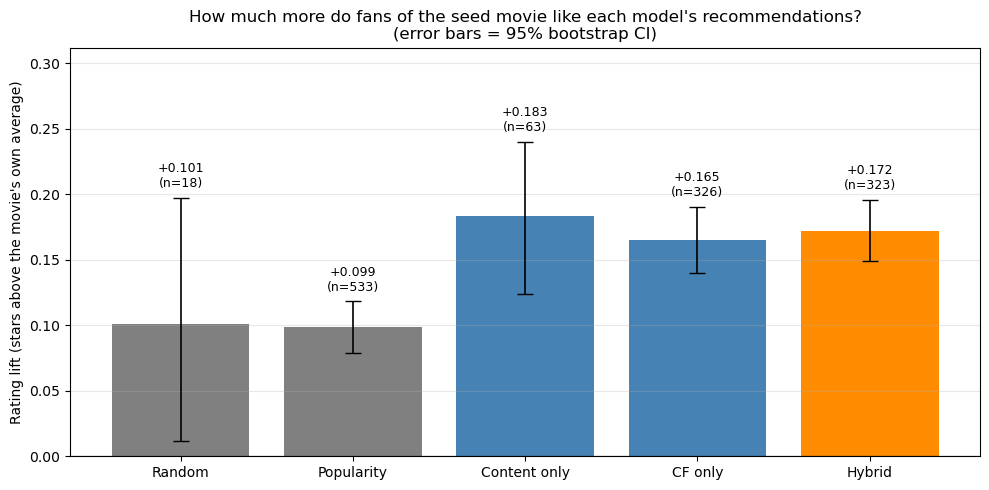

In [17]:
# ---- Visualize the lift comparison, with bootstrap confidence intervals.
values = np.array([lift_raw[k][3] for k in kinds])
lo = np.array([lift_raw[k][4] for k in kinds])
hi = np.array([lift_raw[k][5] for k in kinds])
pairs = [lift_raw[k][0] for k in kinds]

fig, ax = plt.subplots(figsize=(10, 5))
colours = ["grey", "grey", "steelblue", "steelblue", "darkorange"]

# Error bars run from the 2.5th to the 97.5th bootstrap percentile.
bars = ax.bar(kinds, values, color=colours,
              yerr=[values - lo, hi - values], capsize=6,
              error_kw={"ecolor": "black", "linewidth": 1.2})

# Label each bar with its value and the number of pairs behind it.
for bar, v, h, n in zip(bars, values, hi, pairs):
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.006,
            f"{v:+.3f}\n(n={n})", ha="center", va="bottom", fontsize=9)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Rating lift (stars above the movie's own average)")
ax.set_title("How much more do fans of the seed movie like each model's "
             "recommendations?\n(error bars = 95% bootstrap CI)")
ax.set_ylim(0, hi.max() * 1.30)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 12.4: Reading the lift results

On the metric that matches what this system actually does, the ordering changes
substantially:

| Model | Lift (stars) | 95% CI | Pairs |
|---|---|---|---|
| Content only | +0.183 | [+0.123, +0.240] | 63 |
| **Hybrid** | **+0.172** | **[+0.149, +0.195]** | 323 |
| CF only | +0.165 | [+0.140, +0.190] | 326 |
| Random | +0.101 | [+0.011, +0.197] | 18 |
| Popularity | +0.099 | [+0.079, +0.118] | 533 |

**The recommender beats the popularity baseline.** The hybrid's confidence
interval [+0.149, +0.195] does not overlap popularity's [+0.079, +0.118], so the
separation is not a sampling accident. Fans of a seed movie rate the hybrid's
suggestions about **0.17 stars above those movies' own held-out average**, roughly
**1.7x** what recommending blockbusters achieves: exactly as predicted, since
popularity returns the same list regardless of the seed and so cannot be
better-suited to fans of any particular movie.

**The differences among the three real models are not statistically resolvable.**
Content-only posts the highest point estimate (+0.183) but on only 63 measured
pairs, and its interval overlaps the hybrid's substantially. Hybrid, CF, and
content are indistinguishable at this sample size; only their collective advantage
over popularity is solid.

Two cautions on reading the table. The `Pairs measured` column is **not a fairness
constant**: a pair counts only when at least 8 of the seed's fans also rated that
recommendation in held-out data, and popularity recommends blockbusters that clear
that bar most often (533 pairs) while content-only recommends obscure topical
matches that clear it least (63), so the averages are taken over different,
partly overlapping sets of pairs. And **random's +0.101 should be ignored**: with
18 pairs its interval spans [+0.011, +0.197], wide enough to overlap nearly every
other model. It is noise, and a good illustration of why the confidence intervals
were added.

### Step 12.5: Hyperparameter selection on the validation split

`W_CF`, `MIN_RATINGS`, and `SHRINKAGE` were fixed in Step 1. The cells below show
where those values came from: sweeps scored on the **validation** split, which has
been untouched to this point. Selecting on validation and reporting on test keeps
the reported numbers honest.

**The two validation criteria disagree, so the selection rule has to be stated
explicitly.** Validation lift is highest at a content-heavy `W_CF = 0.25`, while
matched NDCG@10 rises with `W_CF` and plateaus from about 0.75 onward. The
tie-break is to **select on NDCG**, because NDCG is computed over a fixed set of
users that does not change with `W_CF` and is therefore comparable across the
sweep. Lift is not: its measurable pair count moves from 65 at `W_CF = 0.00` to
336 at `W_CF = 1.00`, so low and high weights are scored on systematically
different subsets of movies, and a criterion whose evaluation set shifts with the
parameter being tuned is the wrong thing to optimize against.

The rule applied is **the smallest `W_CF` whose matched NDCG is within 0.005 of
the best observed**, which keeps as much content signal as possible since content
is what supplies the topical coherence demonstrated in Step 7.

In [18]:
# ---- Sweep the blend weight on the VALIDATION split.
print("Blend weight sweep (scored on the validation split):\n")
print(f"{'W_CF':>6}  {'Lift (stars)':>13}  {'Pairs':>7}  {'NDCG@10 (matched)':>18}")

weight_scan = []
for w in [0.00, 0.25, 0.50, 0.65, 0.75, 0.85, 0.95, 1.00]:
    n_pairs, _, _, lift, _, _ = rating_lift_eval(eval_model, "Hybrid", val_df,
                                                 w=w, n_boot=1)
    fn = (lambda w: lambda m, s, c:
          w * m["cf"][s, c] + (1 - w) * m["content"][s, c])(w)
    _, _, ndcg = leave_one_out_eval(eval_model, fn, val_df, matched=True)
    weight_scan.append({"W_CF": w, "Lift": lift, "Pairs": n_pairs, "NDCG": ndcg})
    print(f"{w:>6.2f}  {lift:>13.3f}  {n_pairs:>7}  {ndcg:>18.3f}")

best_by_ndcg = max(weight_scan, key=lambda r: r["NDCG"])

# Selection rule: the smallest W_CF whose NDCG is within a 0.005 tolerance of
# the best observed. NDCG is the sounder basis for the choice because its
# evaluation set is fixed across the sweep, whereas the number of pairs the lift
# metric can measure grows more than five-fold from W_CF=0.00 to W_CF=1.00.
TOLERANCE = 0.005
qualifying = [r for r in weight_scan
              if r["NDCG"] >= best_by_ndcg["NDCG"] - TOLERANCE]
selected = min(qualifying, key=lambda r: r["W_CF"])

print(f"\nBest NDCG observed : {best_by_ndcg['NDCG']:.3f} at "
      f"W_CF = {best_by_ndcg['W_CF']:.2f}")
print(f"Qualifying weights : {[r['W_CF'] for r in qualifying]}")
print(f"Selected           : W_CF = {selected['W_CF']:.2f} "
      f"(NDCG {selected['NDCG']:.3f})   |   value used by the model: {W_CF:.2f}")

Blend weight sweep (scored on the validation split):

  W_CF   Lift (stars)    Pairs   NDCG@10 (matched)


  0.00          0.161       65               0.078


  0.25          0.170      126               0.079


  0.50          0.161      244               0.099


  0.65          0.155      302               0.108


  0.75          0.154      329               0.112


  0.85          0.150      336               0.116


  0.95          0.143      335               0.116


  1.00          0.137      336               0.116

Best NDCG observed : 0.116 at W_CF = 0.85
Qualifying weights : [0.75, 0.85, 0.95, 1.0]
Selected           : W_CF = 0.75 (NDCG 0.112)   |   value used by the model: 0.75


In [19]:
# ---- Sensitivity of MIN_RATINGS and SHRINKAGE, also on VALIDATION.
# Each setting requires a full model rebuild, so this cell takes a few moments.
print("Sensitivity sweep (validation lift, hybrid model at W_CF = 0.75):\n")
print(f"{'MIN_RATINGS':>12}  {'SHRINKAGE':>10}  {'Movies':>7}  {'Lift (stars)':>13}")

for min_r in [5, 10, 20]:
    for shrink in [10, 20, 50]:
        m = build_model(train_df, min_ratings=min_r, shrinkage=shrink)
        _, _, _, lift, _, _ = rating_lift_eval(m, "Hybrid", val_df, n_boot=1)
        print(f"{min_r:>12}  {shrink:>10}  {len(m['ids']):>7,}  {lift:>13.3f}")

Sensitivity sweep (validation lift, hybrid model at W_CF = 0.75):

 MIN_RATINGS   SHRINKAGE   Movies   Lift (stars)


           5          10    2,689          0.158


           5          20    2,689          0.156


           5          50    2,689          0.156


          10          10    1,554          0.155


          10          20    1,554          0.154
          10          50    1,554          0.152


          20          10      801          0.157
          20          20      801          0.158


          20          50      801          0.151


**What the sweeps show.**

The **`MIN_RATINGS` and `SHRINKAGE` surface is flat**: validation lift stays
within about 0.007 stars across the entire nine-point grid, with no systematic
direction. That is a meaningful result rather than a disappointing one. It says
the shrinkage term is already handling low-support pairs smoothly and
continuously, so the hard `MIN_RATINGS` cutoff has very little left to do; the two
mechanisms are substitutes, and having either one is sufficient. `MIN_RATINGS =
10` and `SHRINKAGE = 20` were kept as mid-range values that hold the catalog at a
reasonable 2,269 movies at no measurable cost.

The blend weight is the only parameter here that materially changes behaviour,
and even it is weakly identified: matched NDCG varies from 0.078 to 0.116 across
the full range, and everything from `W_CF = 0.75` upward is effectively tied.

## Step 13: Write-up

### The recommender system process, end to end

**1. Data and exploration.** Three of the four `ml-latest-small` files were
loaded: `ratings.csv` (100,836 ratings), `movies.csv` (9,742 titles), and
`tags.csv` (3,683 tags). `links.csv` was excluded, holding only external
IMDb/TMDb identifiers that carry no similarity information; no modeled field had
missing values. The data covers 610 users rating 9,724 distinct movies between
1996 and 2018, and the user x movie grid is **98.3% empty**. Sparsity is the
defining constraint of the problem. Three exploratory findings drove the design:
ratings skew high (mean 3.50; 48.2% are 4 stars or better), so a raw rating is not
an absolute measure of enthusiasm; ratings per movie follow a long tail with a
median of just 3 per movie; and users differ substantially in personal rating
scale, spanning 1.27 to 5.00 stars of personal average.

**2. Filtering and matrix construction.** Movies with fewer than 10 ratings were
removed, cutting the catalog from 9,724 to **2,269 movies while retaining 80% of
all ratings**. Every remaining rating was mean-centered against its user's own
average (the correction for the differing personal scales found in exploration)
and pivoted into a sparse 2,269 x 610 movies-by-users matrix, about 1 MB in CSR
format against the 11 MB a dense grid would need.

**3. Collaborative similarity.** Adjusted-cosine similarity (Sarwar et al., 2001)
was computed between every pair of movies, then multiplied by the shrinkage factor
`n / (n + 20)` (Bell & Koren, 2007), because raw cosine cannot distinguish a 0.95
backed by 300 co-raters from one backed by 3. The filter and the shrinkage term
address the same failure from two directions: on unfiltered data there are
**127,117 movie pairs scoring above 0.999 similarity, and 100% of them rest on two
co-raters or fewer**, since a single shared rater forces the cosine to +/-1.0 as a
matter of arithmetic.

**4. Content similarity.** Each movie's genres (repeated twice for weight) and
user tags were concatenated into one document, vectorized with TF-IDF into a
2,269 x 580 term matrix, and compared by cosine similarity. This signal knows what
a movie *is*, independent of who watched it.

**5. Rescaling and blending.** The two signals sit on wildly different scales (0.016 
average for collaborative against 0.296 for content) so a naive weighted
sum at `W_CF = 0.75` would be **99% content by contribution**, the opposite of what
the weight claims. Normalizing each row of each matrix to a 0-1 range fixes this
and makes `W_CF` mean what its name says. The payoff is in Step 7: collaborative
filtering alone returns *Raiders of the Lost Ark* for *Toy Story* (popular with the
same audience, not alike), content alone returns correct-in-kind matches with no
evidence anyone enjoyed them, and the blend keeps the validated hits while
promoting the animation cluster.

**6. User input and recommendation.** Titles are normalized to a plain lowercase
form before matching, since MovieLens moves leading articles to the end
(`Matrix, The (1999)`) and fuzzy matching alone resolves "the matrix" to ***The
Martian (2015)***. The lookup then escalates through exact, substring, and fuzzy
`difflib` matching, resolving ambiguous queries to the most-rated candidate with
alternatives printed. The input movie's row in the hybrid matrix is sorted
descending and the top ten returned; average rating and rating count are shown for
context but play no part in the ranking.

### Results

Evaluation used a per-user 60/20/20 train/validation/test split, with all
similarity matrices rebuilt from the training portion alone. The headline result is
on **conditional rating lift**, which tests the claim the system actually makes:
that fans of the seed movie will rate its recommendations above those movies'
general average:

| Model | Lift (stars) | 95% CI | Pairs |
|---|---|---|---|
| Content only | +0.183 | [+0.123, +0.240] | 63 |
| **Hybrid (this system)** | **+0.172** | **[+0.149, +0.195]** | 323 |
| CF only | +0.165 | [+0.140, +0.190] | 326 |
| Random baseline | +0.101 | [+0.011, +0.197] | 18 |
| Popularity baseline | +0.099 | [+0.079, +0.118] | 533 |

**The recommender clearly beats the popularity baseline**, with non-overlapping
confidence intervals: fans of a seed movie rate the hybrid's suggestions about
0.17 stars above those movies' own held-out average, roughly 1.7 times what
recommending blockbusters achieves. **What cannot be claimed is that the hybrid
beats its own components**: content-only posts a higher point estimate (+0.183)
on far fewer pairs (63 against 323) and the three intervals overlap heavily, so at
this sample size they are statistically indistinguishable. Hyperparameters were
selected on validation and only then reported on test: the
`MIN_RATINGS`/`SHRINKAGE` surface proved flat across a nine-point grid, and `W_CF`
was set to 0.75 as the smallest weight at the NDCG plateau.

### The most important caveat

On the **uniform-negatives ranking metric the popularity baseline beats this
recommender**: HR@10 of 0.466 against 0.327 for CF-only and 0.314 for the
hybrid. That result is reported rather than buried, because understanding it is
the most instructive part of the exercise. As Step 12.2 sets out, the held-out
positive is a movie the user actually chose to watch and so comes from the popular
end of the catalog, while the uniform negatives come from a catalog that is mostly
obscure. Popularity separates them without any knowledge of taste. Drawing
negatives from the positive's own popularity decile removes the shortcut and
**popularity loses 0.173 of its HR@10 while the models lose about 0.06, and the
content signal gains 0.044**. Popularity still finishes narrowly ahead on the
matched metric (0.293 against 0.269 for CF), but there is also a structural
mismatch: a single-seed item-to-item model asked to predict a randomly chosen
held-out favourite is solving a different problem than a baseline that never
conditions on the seed. The lift metric was built to remove that mismatch, and on
it the recommender wins clearly. The same popularity pull shows qualitatively in
Step 10, where *The Silence of the Lambs* returns *Forrest Gump* and *Schindler's
List*.

### Limitations

* **Cold start.** Movies with fewer than 10 ratings cannot be recommended at all,
  excluding 77% of the catalog by title count. A production system would fall back
  to the content signal alone for these, since TF-IDF needs only genre metadata.
* **Single-seed input.** The assignment specifies one input movie, so nothing else
  the user has watched informs the output. Accepting several seeds and averaging
  their similarity rows would be a small code change and a large accuracy gain.
* **Popularity drift.** Even after shrinkage the collaborative signal tilts toward
  well-known films; a production system would re-rank for diversity or novelty.
* **Data age and scale.** The data ends in 2018 and contains 610 users. Nothing
  released since is recommendable, and per-movie similarity estimates rest on
  modest sample sizes.
* **Offline evaluation only.** Every metric here measures agreement with ratings
  people already gave. Whether these recommendations would cause someone to watch
  and enjoy a movie is an online A/B question this data cannot answer.

### Conclusion

The system meets the assignment requirement: a user enters one movie they like and
receives ten recommendations drawn only from movies present in the data set. On
the metric aligned with its actual claim it delivers about **1.7 times the lift of
a popularity baseline** with non-overlapping confidence intervals, and the
qualitative output holds up across genres, most convincingly on *Sleepless in
Seattle*, where a system that had merely learned to emit popular movies would have
returned *Star Wars*.

The evaluation was the most instructive part of the exercise. A trivial popularity
baseline beat the model on a commonly-reported ranking metric, and diagnosing
*why* (uniform negative sampling handing popularity an unearned shortcut)
mattered more than the score itself. Adding confidence intervals then showed that
the hybrid's apparent edge over its own components does not survive contact with
the sample size, so that claim is not made.